In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 14.5 MB/s eta 0:00:00


# Training

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, jaccard_score
from sklearn.metrics import jaccard_score
from sklearn.model_selection import train_test_split
from torchmetrics import JaccardIndex, Accuracy, F1Score, Precision, Recall  # Import all necessary

# Define U-Net architecture
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        # Encoder (downsampling)
        self.enc1 = self.conv_block(n_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        # Decoder (upsampling)
        self.dec1 = self.upconv(512, 256)
        self.dec2 = self.upconv(256, 128)
        self.dec3 = self.upconv(128, 64)
        self.dec4 = self.upconv(64, 64)
        self.dec5 = nn.Conv2d(64, n_classes, kernel_size=1)

        # Initialize with kaiming normal
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
              nn.init.kaiming_normal_(module.weight)


    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def upconv(self, in_ch, out_ch):
        return nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        # Encoder
        # print(x.shape)
        e1 = self.enc1(x)
        # print(e1.shape)
        e2 = self.enc2(e1)
        # print(e2.shape)
        e3 = self.enc3(e2)
        # print(e3.shape)
        e4 = self.enc4(e3)
        # print(e4.shape)

        # Decoder
        d1 = self.dec1(e4)
        # print(d1.shape)
        d2 = self.dec2(d1)
        # print(d2.shape)
        d3 = self.dec3(d2)
        # print(d3.shape)
        d4 = self.dec4(d3)
        # print(d4.shape)
        out = self.dec5(d4)
        # print(out.shape)

        return torch.sigmoid(out)

class LakeDataset(Dataset):
    def __init__(self, image_folder, mask_folder, transform=None):
        self.image_folder = image_folder
        self.mask_folder = mask_folder
        self.transform = transform
        self.file_names = [f for f in os.listdir(image_folder) if f.endswith('.npy')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_name = self.file_names[idx]
        image_path = os.path.join(self.image_folder, file_name)
        mask_path = os.path.join(self.mask_folder, file_name)

        image = np.load(image_path)
        mask = np.load(mask_path)

        # Check the shape of the loaded data
        # print(f"Image shape: {image.shape}")
        # print(f"Mask shape: {mask.shape}")

        # Convert to grayscale if needed
        if image.shape == (64, 64, 3):
            image = np.transpose(image,(2,0,1))  # Transpose to (3, 64, 64)

        # Ensure image shape is (1, 64, 64)
        #image = image.reshape((1, 64, 64))
        if mask.shape == (64, 64, 1):
            image = np.transpose(mask,(2,0,1))
        # Normalize mask values
        mask = mask.astype(np.float32) / 255.0  # Assuming masks are in 0-255 range

        # Convert to torch tensors
        image = torch.from_numpy(image).float()
        mask = torch.from_numpy(mask).float()

        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return image, mask, file_name  # Return file name for identification

# Training function
def train(model, dataloader, criterion, optimizer, device):
    model.train()
    for images, masks, _ in dataloader:
        images, masks = images.to(device), masks.to(device)

        # Use bilinear interpolation for resizing the mask
        # masks = torch.nn.functional.interpolate(masks, size=(32, 32), mode='bilinear', align_corners=False)
        optimizer.zero_grad()
        outputs = model(images)
        outputs=torch.squeeze(outputs)
        # print(masks.shape)
        # print(outputs.shape)
        loss = criterion(outputs, masks)
        loss.backward()

        # Gradient clipping (add this line)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1)  # Adjust clip value if needed

        optimizer.step()

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    iou_metric = JaccardIndex(task="binary")  # Specify 'binary' task
    accuracy_metric = Accuracy(task="binary")  # Add 'task="binary"'
    f1_metric = F1Score(task="binary")
    precision_metric = Precision(task="binary")
    recall_metric = Recall(task="binary")

    with torch.no_grad():
        for images, masks, _ in dataloader:
            images, masks = images.to(device), masks.to(device)
            # masks = torch.nn.functional.interpolate(masks, size=(32, 32), mode='bilinear', align_corners=False)
            outputs = model(images)
            outputs=torch.squeeze(outputs)
            loss = criterion(outputs, masks)
            total_loss += loss.item()

            # Threshold predictions AND target masks
            predictions = (outputs > 0.5).float()
            masks = (masks > 0.5).float()  # Threshold target masks

            # Calculate IoU using torchmetrics
            iou = iou_metric(predictions, masks)

            # Calculate other metrics
            accuracy = accuracy_metric(predictions, masks)
            f1 = f1_metric(predictions, masks)
            precision = precision_metric(predictions, masks)
            recall = recall_metric(predictions, masks)

    # Calculate metrics
    test_loss = total_loss / len(dataloader)

    return test_loss, accuracy.item(), f1.item(), recall.item(), precision.item(), iou.item()

# Main execution
def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Hyperparameters
    batch_size = 128
    num_epochs = 200
    learning_rate = 0.0001

    # Data folders
    image_folder = '/content/drive/MyDrive/combined_sent'
    mask_folder = '/content/drive/MyDrive/combined_bin'

    # Define transforms if needed
    transform = None

    # Create dataset
    dataset = LakeDataset(image_folder, mask_folder, transform=transform)

    # Split data into train and test sets
    train_indices, test_indices = train_test_split(
        list(range(len(dataset))), test_size=0.2, random_state=42
    )

    # # Print the test filenames
    # print("Test Filenames:")
    # for idx in test_indices:
    #     print(dataset.file_names[idx])

    train_dataset = torch.utils.data.Subset(dataset, train_indices)
    test_dataset = torch.utils.data.Subset(dataset, test_indices)

    # Create dataloaders
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Initialize model, loss, and optimizer
    model = UNet(n_channels=3, n_classes=1).to(device)  # Assuming single-channel input
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Training loop
    for epoch in range(num_epochs):
        train(model, train_dataloader, criterion, optimizer, device)
        print(f'Epoch {epoch+1}/{num_epochs} completed')

        # Evaluate on test set
        test_loss, accuracy, f1, recall, precision, iou = evaluate(model, test_dataloader, criterion, device)
        print(f'Test Loss: {test_loss:.4f}')
        print(f'Accuracy: {accuracy:.4f}')
        if epoch%20==0:
          torch.save(model.state_dict(), f'/content/drive/MyDrive/lake_segmentation_model_epoch_{epoch}.pth')

    # Save the model
    torch.save(model.state_dict(), 'lake_segmentation_model.pth')

if __name__ == '__main__':
    main()


Epoch 1/200 completed
Test Loss: 0.8282
Accuracy: 0.5072
Epoch 2/200 completed
Test Loss: 0.7453
Accuracy: 0.5338
Epoch 3/200 completed
Test Loss: 0.7040
Accuracy: 0.5593
Epoch 4/200 completed
Test Loss: 0.6766
Accuracy: 0.6169
Epoch 5/200 completed
Test Loss: 0.6605
Accuracy: 0.6659
Epoch 6/200 completed
Test Loss: 0.6449
Accuracy: 0.7100
Epoch 7/200 completed
Test Loss: 0.6289
Accuracy: 0.7436
Epoch 8/200 completed
Test Loss: 0.6147
Accuracy: 0.7719
Epoch 9/200 completed
Test Loss: 0.5990
Accuracy: 0.8011
Epoch 10/200 completed
Test Loss: 0.5823
Accuracy: 0.8281
Epoch 11/200 completed
Test Loss: 0.5674
Accuracy: 0.8502
Epoch 12/200 completed
Test Loss: 0.5513
Accuracy: 0.8718
Epoch 13/200 completed
Test Loss: 0.5369
Accuracy: 0.8886
Epoch 14/200 completed
Test Loss: 0.5244
Accuracy: 0.9007
Epoch 15/200 completed
Test Loss: 0.5116
Accuracy: 0.9111
Epoch 16/200 completed
Test Loss: 0.5003
Accuracy: 0.9185
Epoch 17/200 completed
Test Loss: 0.4906
Accuracy: 0.9238
Epoch 18/200 completed


#prediction

Predicting for im_1_0_0.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


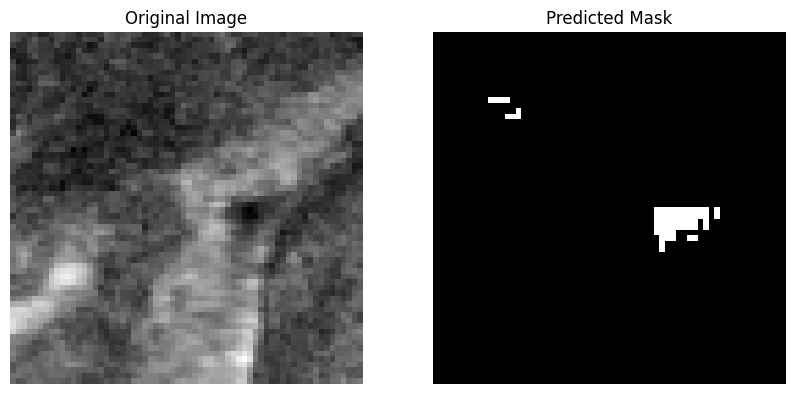

Predicting for im_1_0_1.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


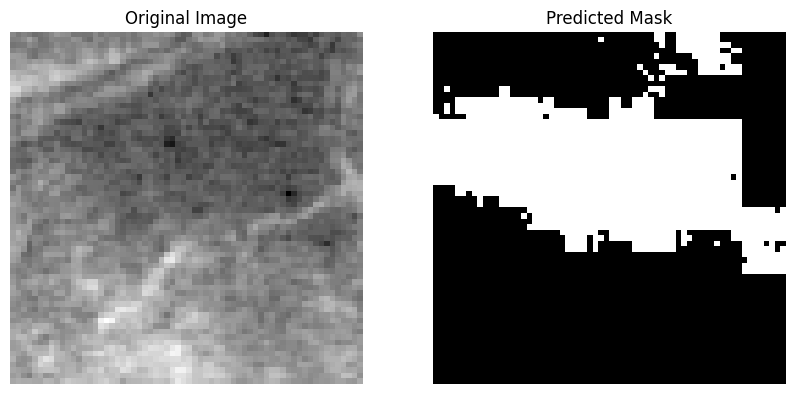

Predicting for im_1_0_2.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


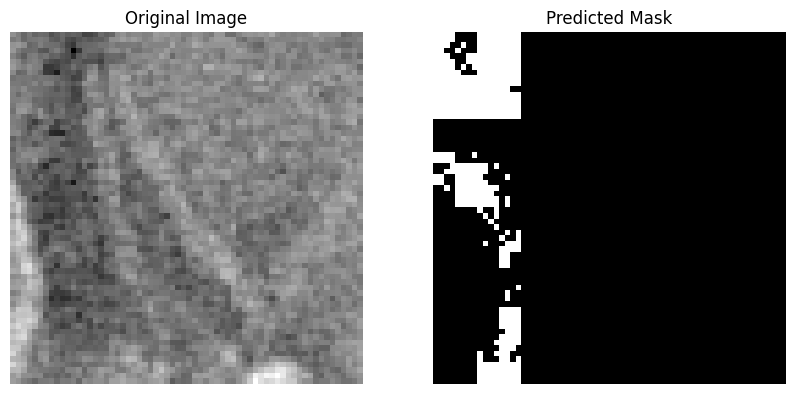

Predicting for im_1_0_3.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


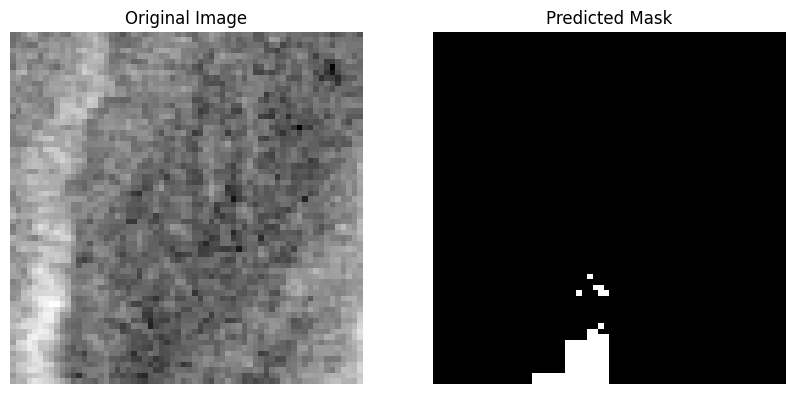

Predicting for im_1_0_4.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


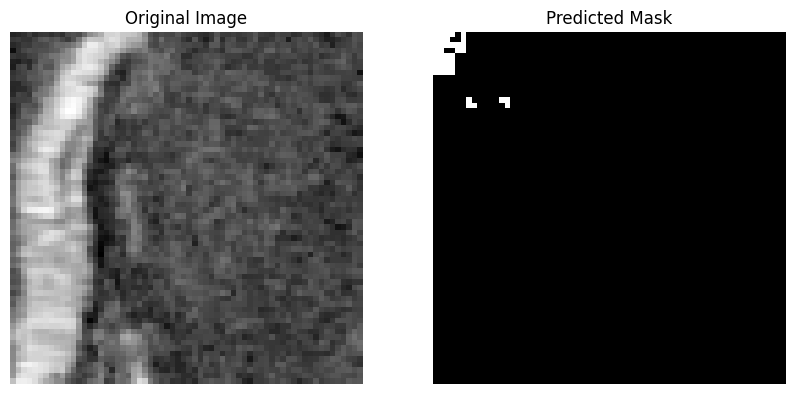

Predicting for im_1_0_5.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


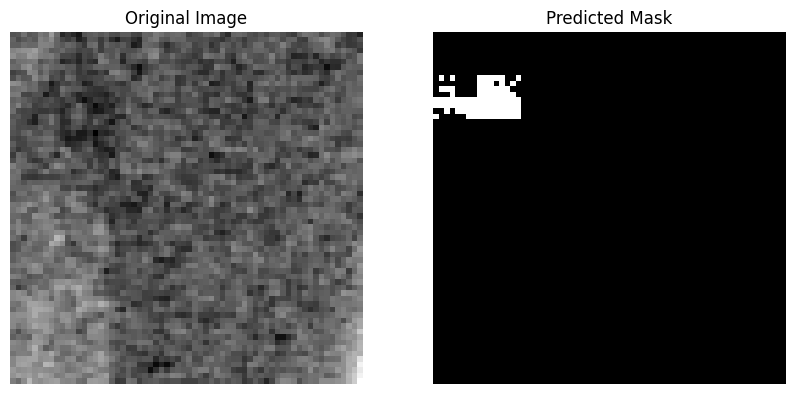

Predicting for im_1_0_6.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


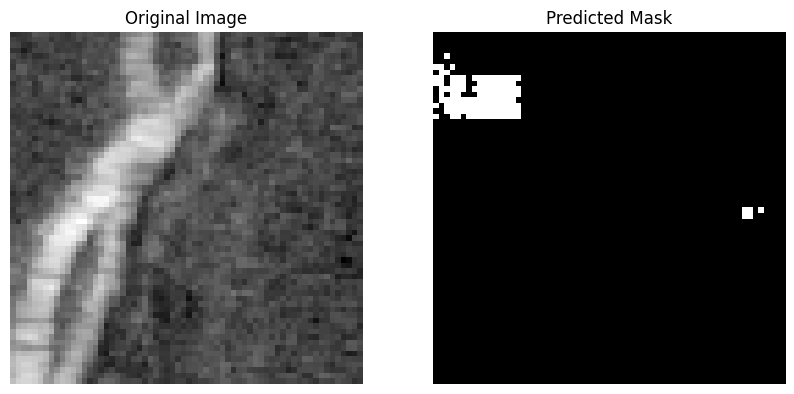

Predicting for im_1_0_7.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


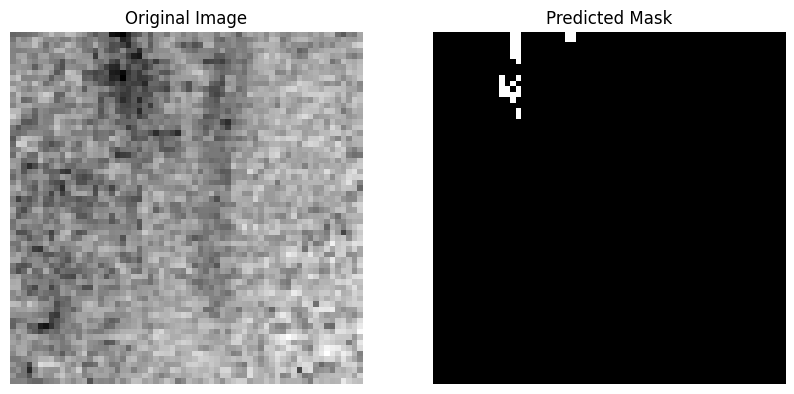

Predicting for im_1_0_8.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


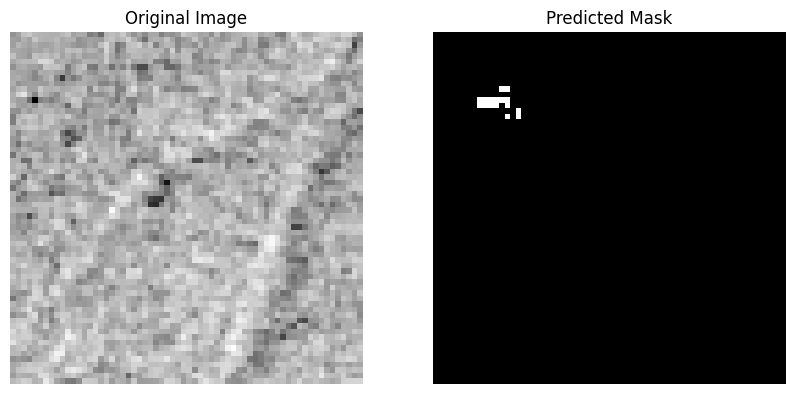

Predicting for im_1_0_9.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


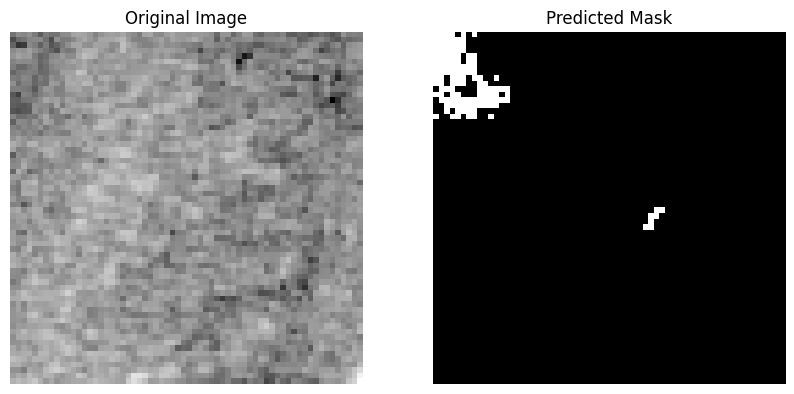

Predicting for im_1_0_10.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


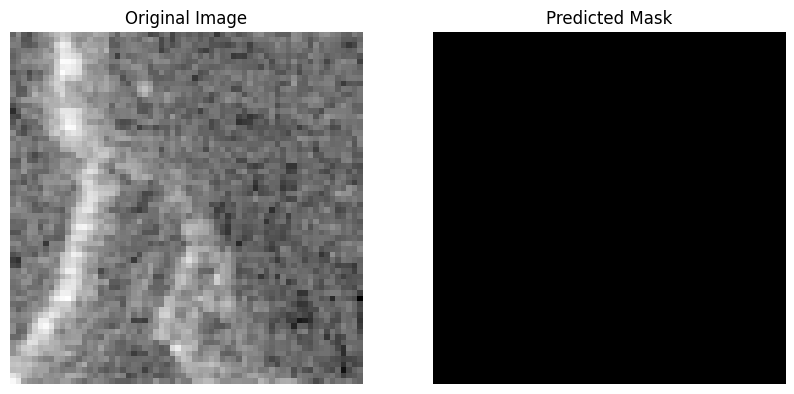

Predicting for im_1_0_11.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


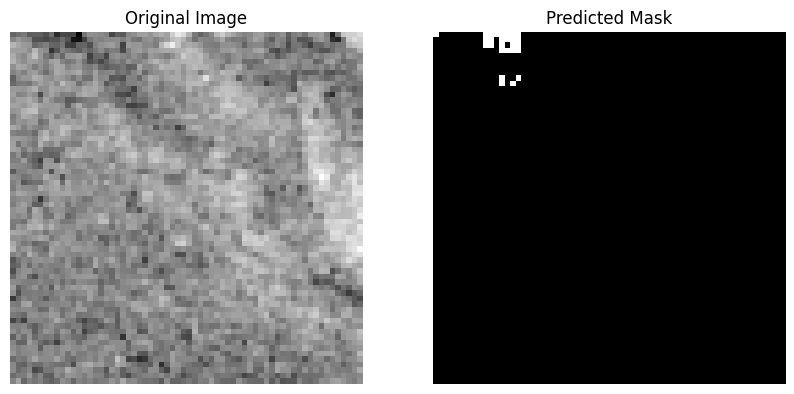

Predicting for im_1_0_12.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


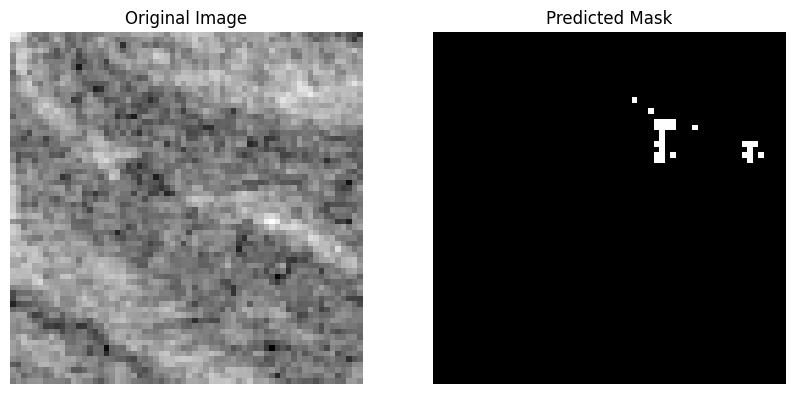

Predicting for im_1_0_13.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


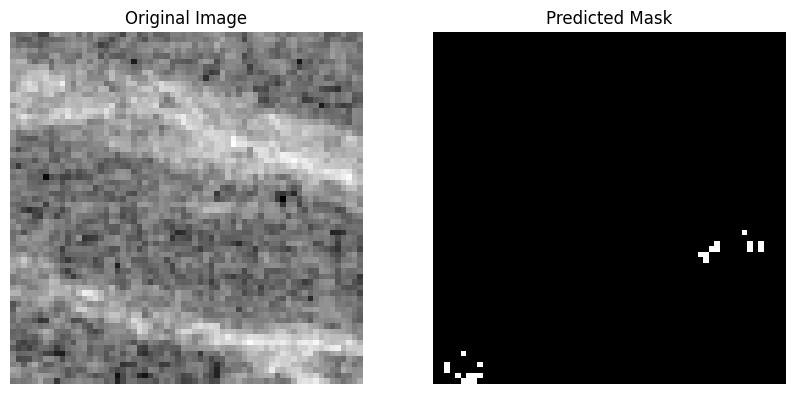

Predicting for im_1_0_14.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


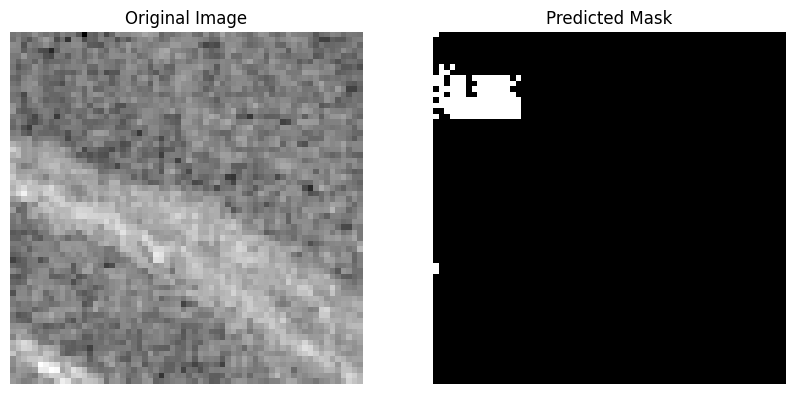

Predicting for im_1_0_15.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


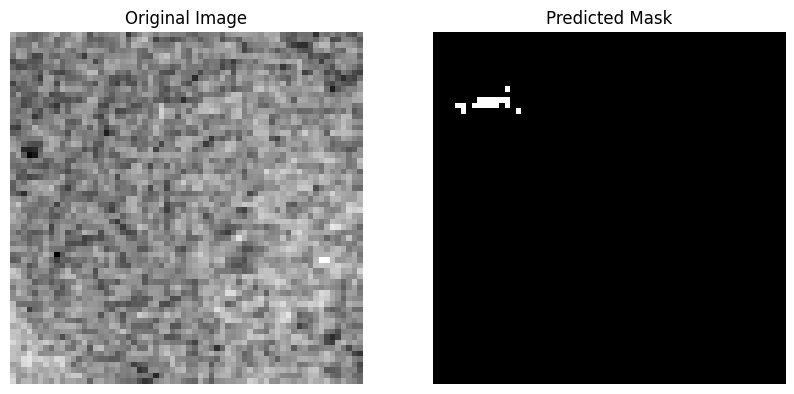

Predicting for im_1_0_16.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


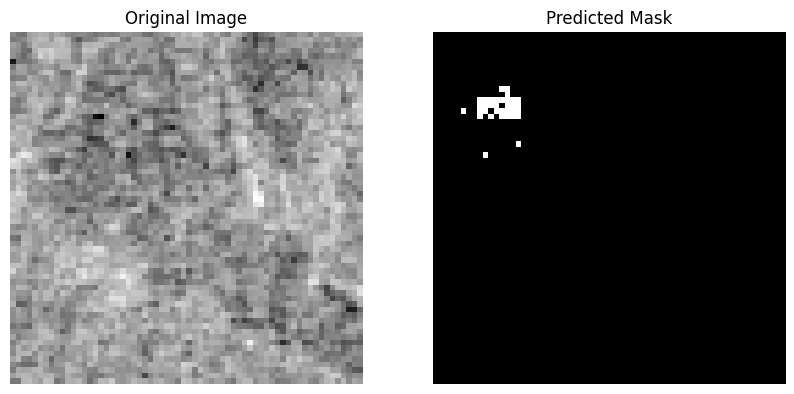

Predicting for im_1_0_17.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


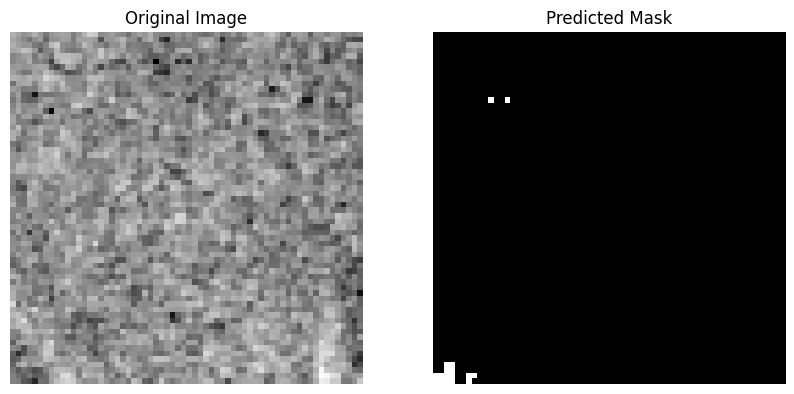

Predicting for im_1_0_18.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


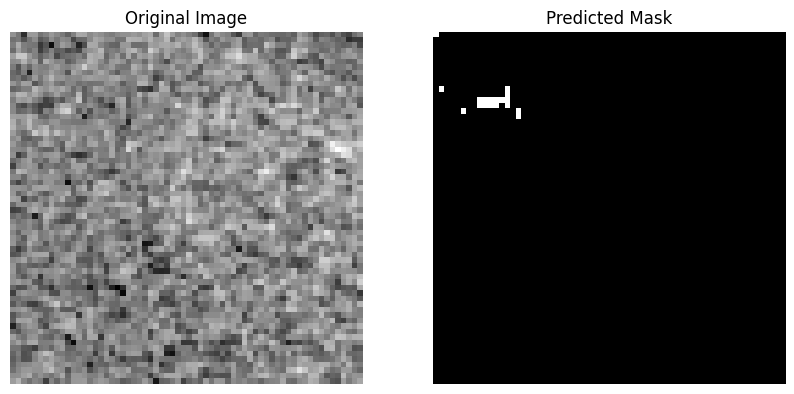

Predicting for im_1_0_19.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


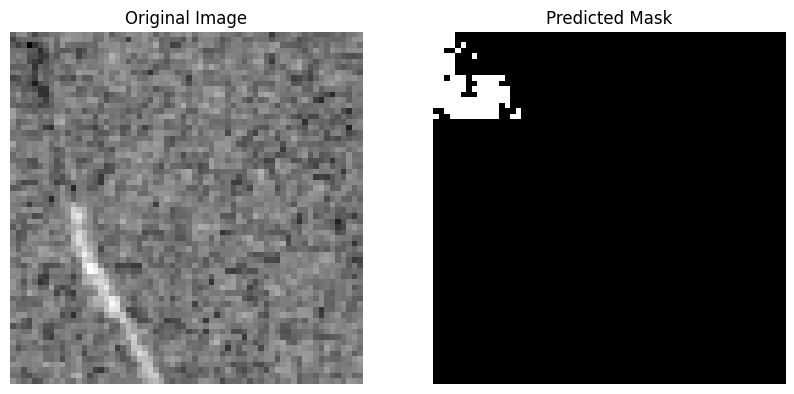

Predicting for im_1_0_20.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


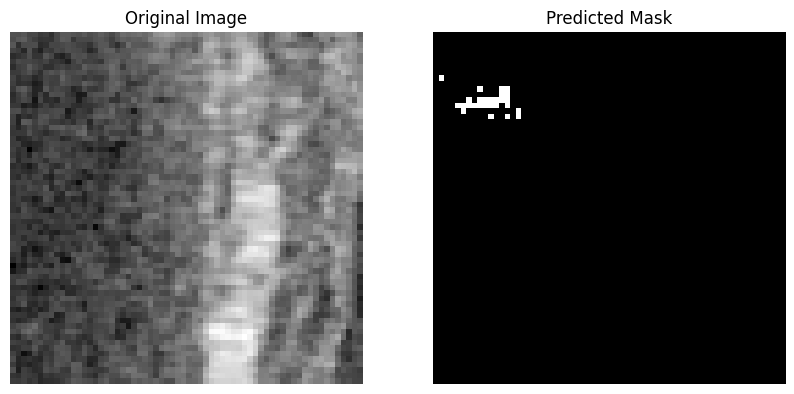

Predicting for im_1_0_21.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


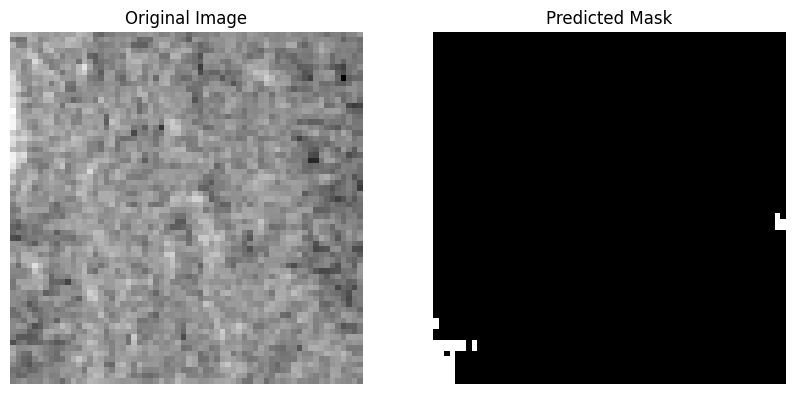

Predicting for im_1_0_22.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


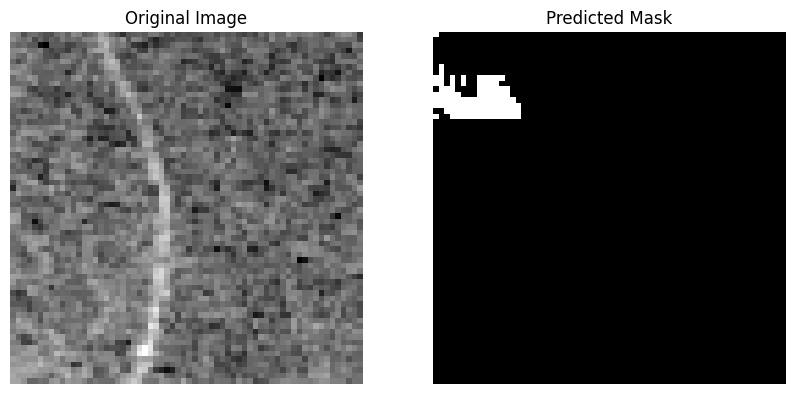

Predicting for im_1_0_23.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


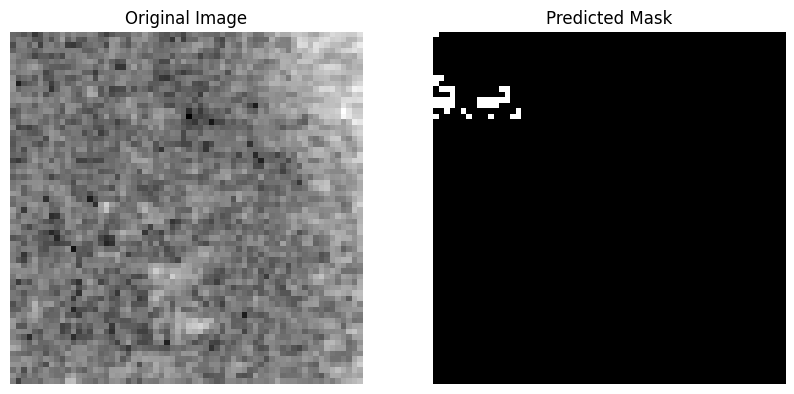

Predicting for im_1_0_24.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


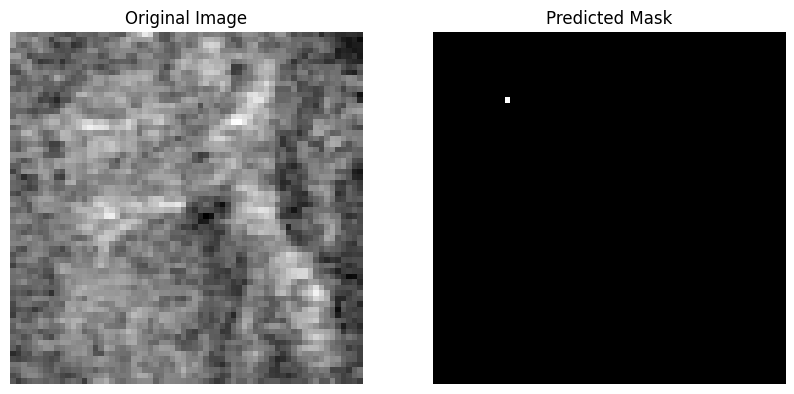

Predicting for im_1_0_25.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


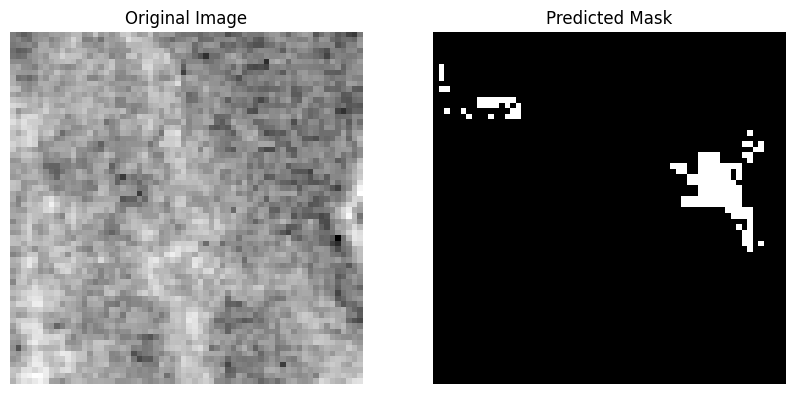

Predicting for im_1_0_26.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


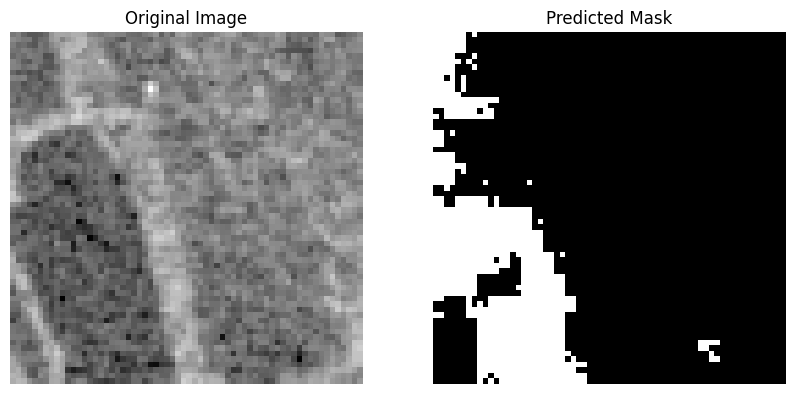

Predicting for im_1_0_27.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


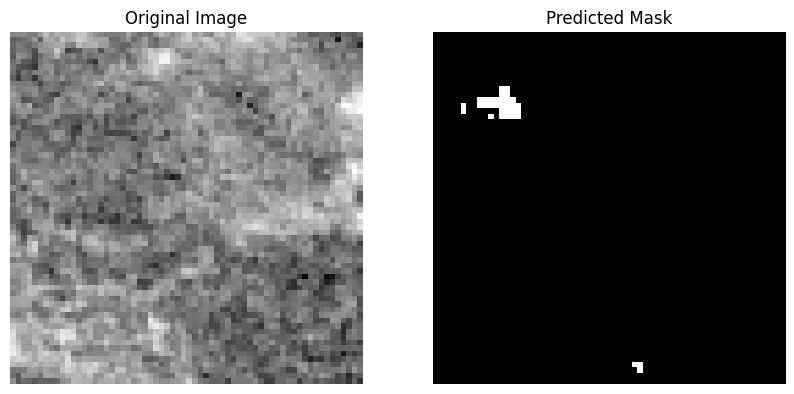

Predicting for im_1_0_28.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


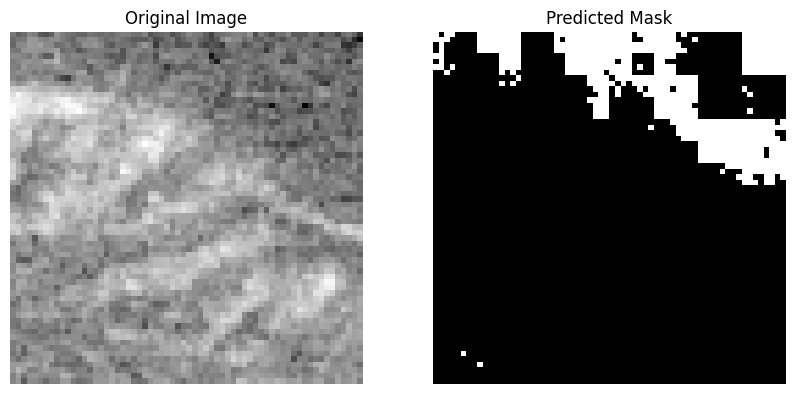

Predicting for im_1_0_29.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


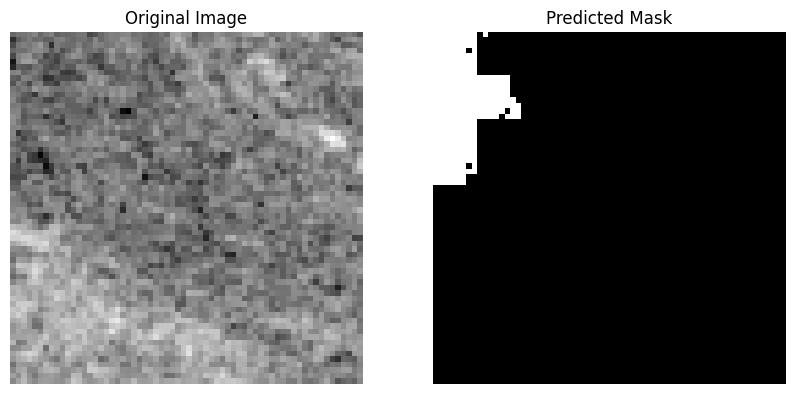

Predicting for im_1_0_30.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


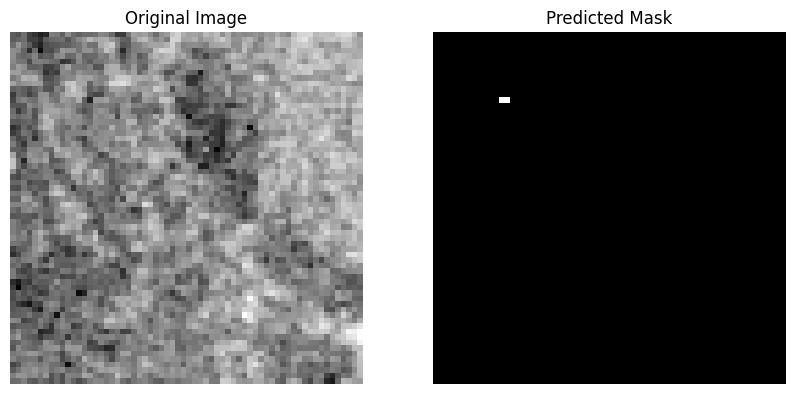

Predicting for im_1_0_31.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


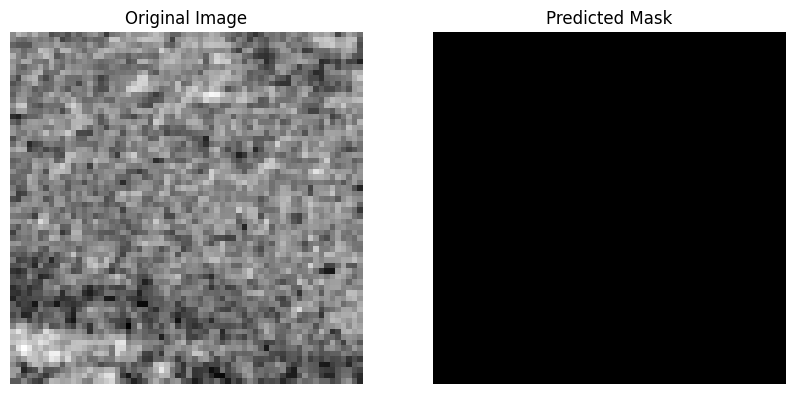

Predicting for im_1_1_0.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


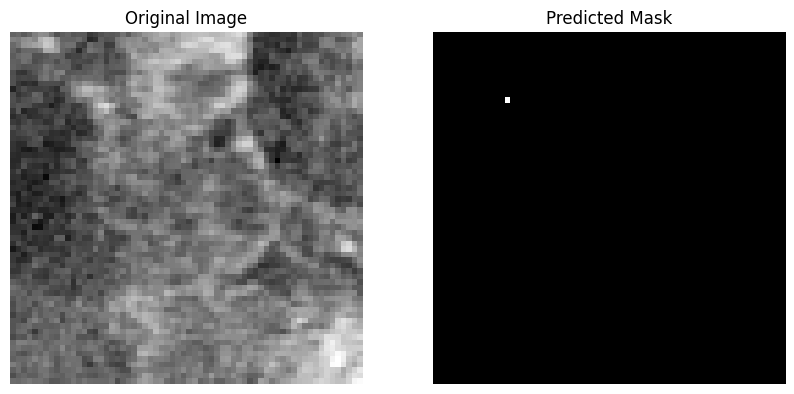

Predicting for im_1_1_1.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


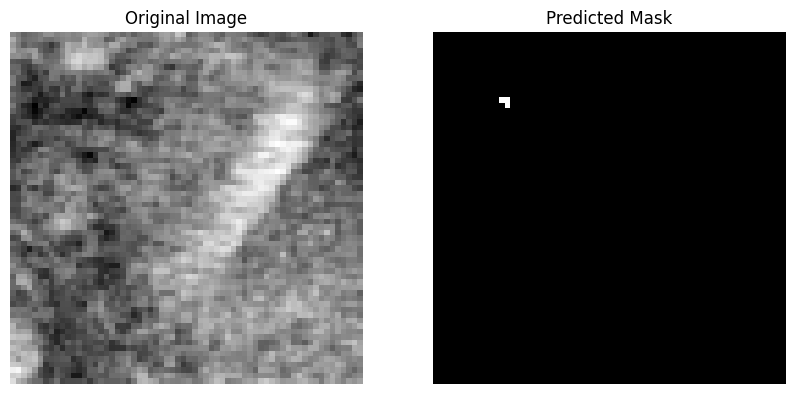

Predicting for im_1_1_2.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


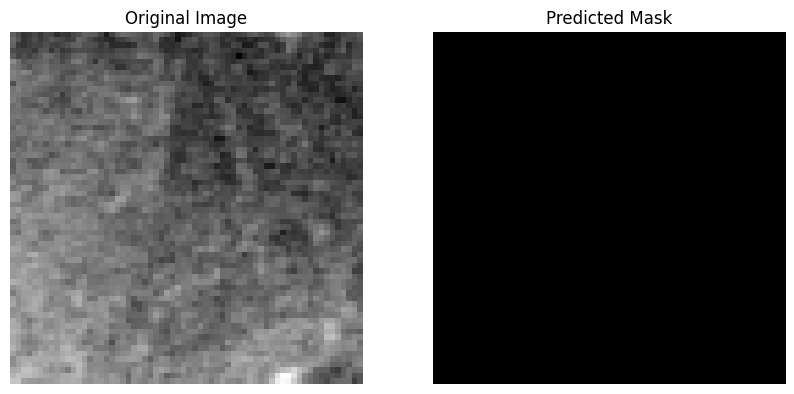

Predicting for im_1_1_3.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


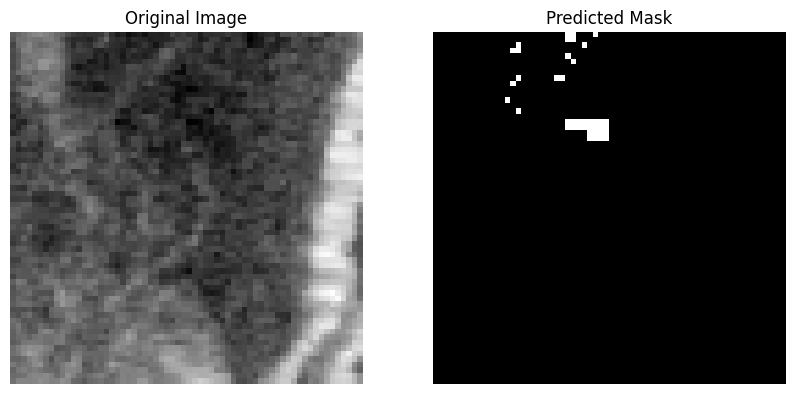

Predicting for im_1_1_4.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


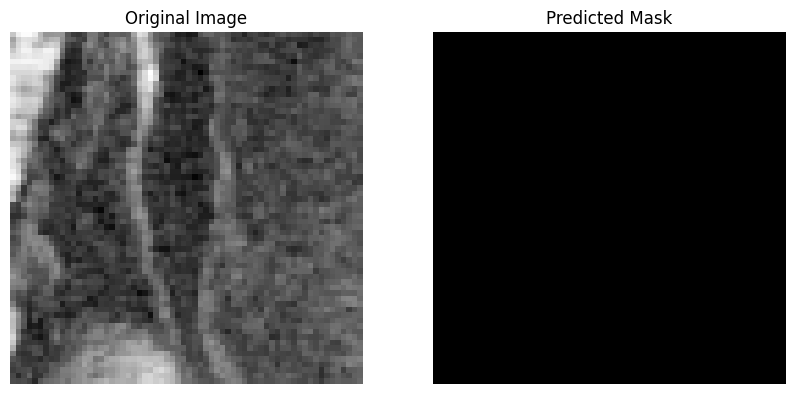

Predicting for im_1_1_5.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


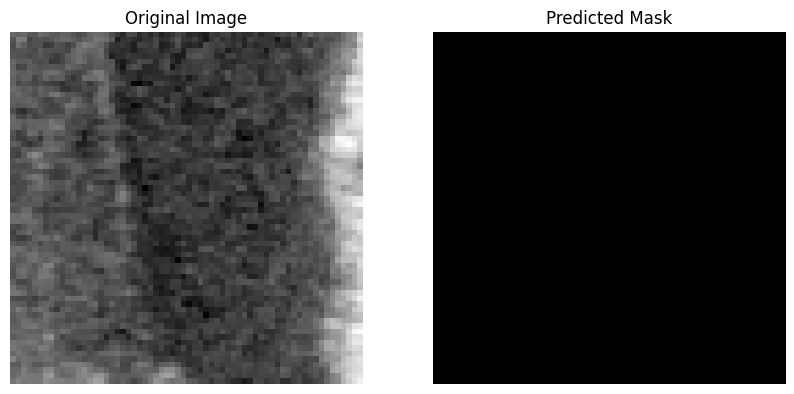

Predicting for im_1_1_6.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


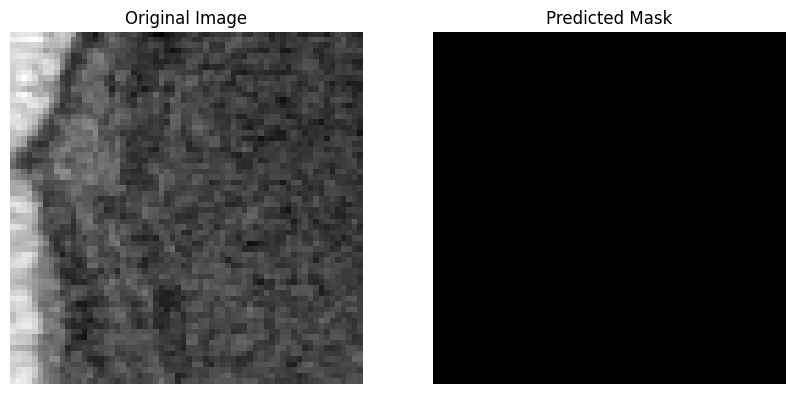

Predicting for im_1_1_7.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


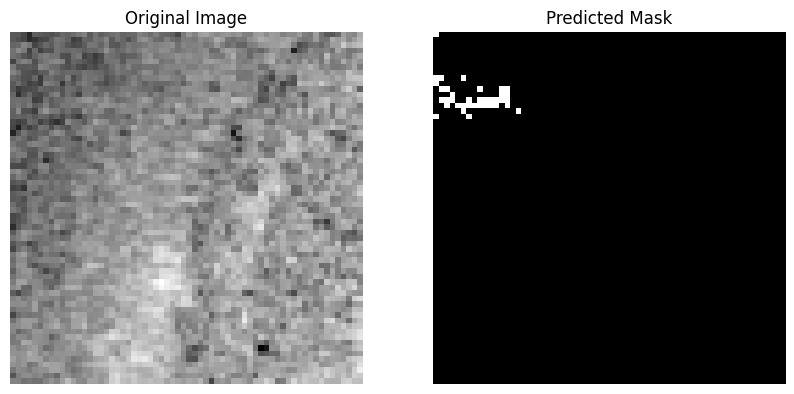

Predicting for im_1_1_8.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


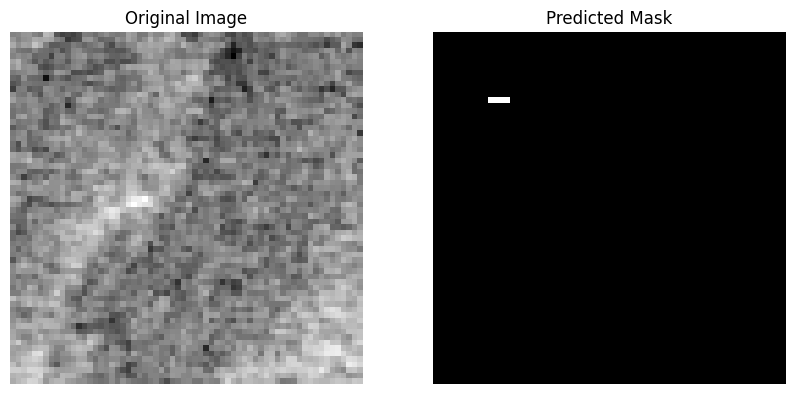

Predicting for im_1_1_9.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


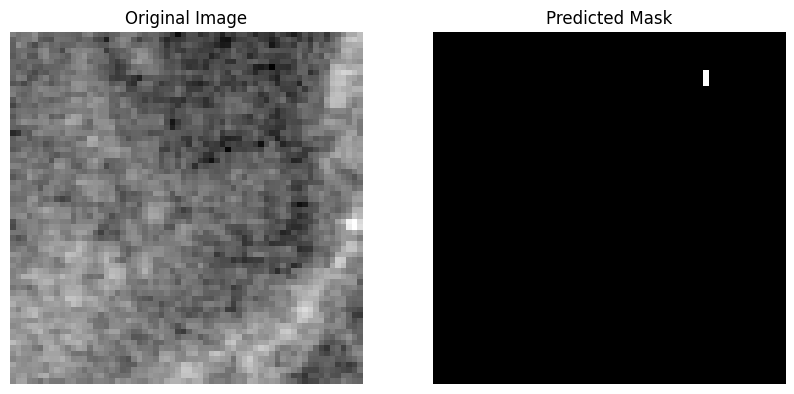

Predicting for im_1_1_10.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


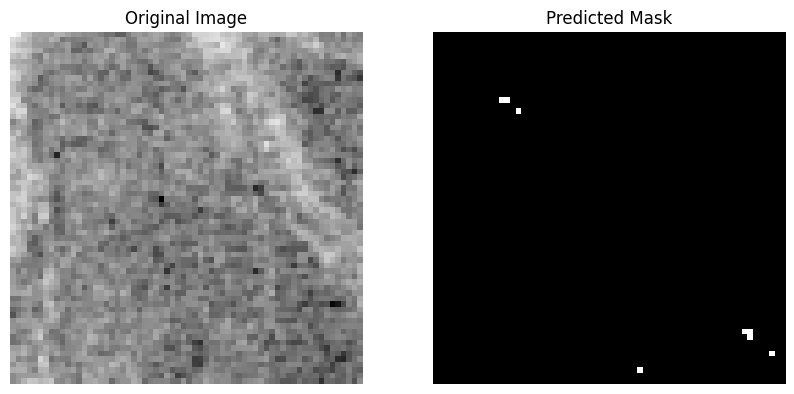

Predicting for im_1_1_11.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


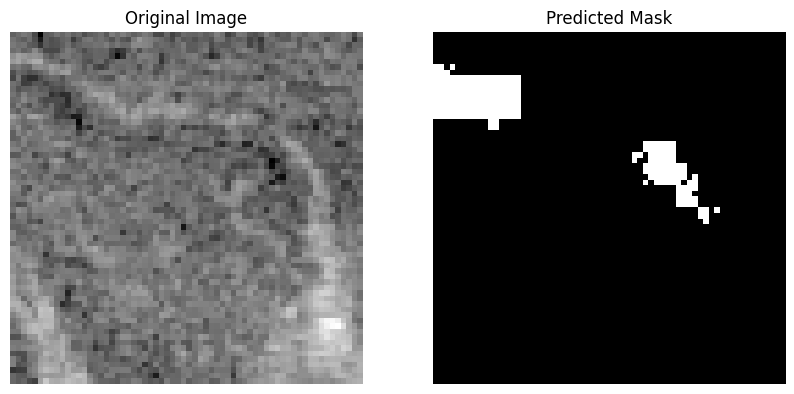

Predicting for im_1_1_12.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


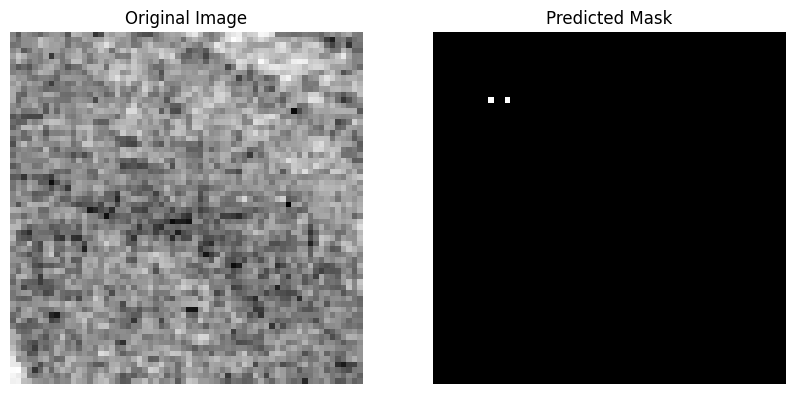

Predicting for im_1_1_13.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


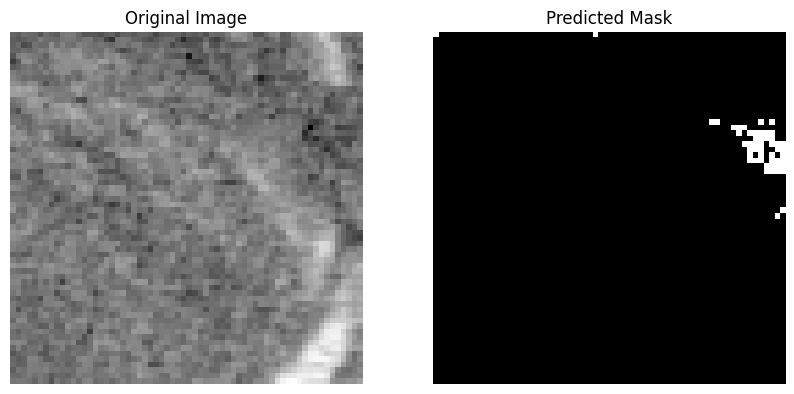

Predicting for im_1_1_14.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


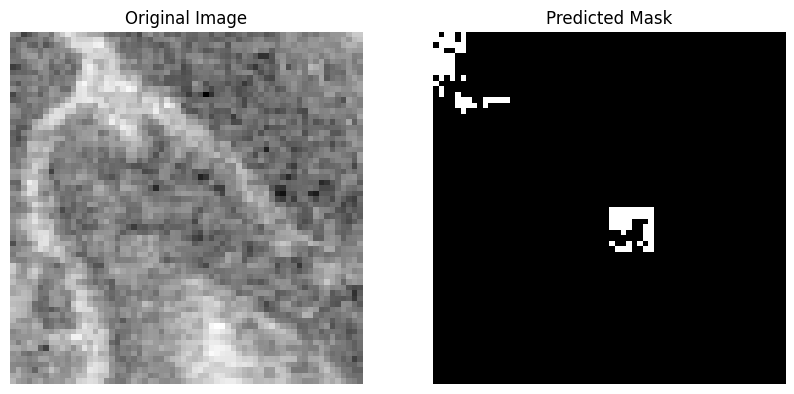

Predicting for im_1_1_15.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


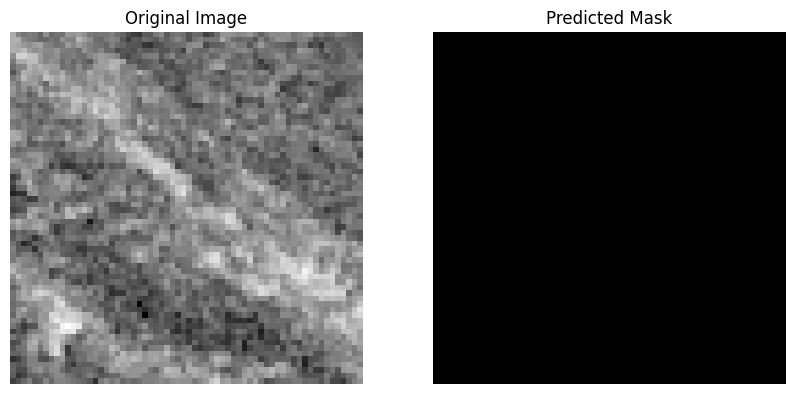

Predicting for im_1_1_16.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


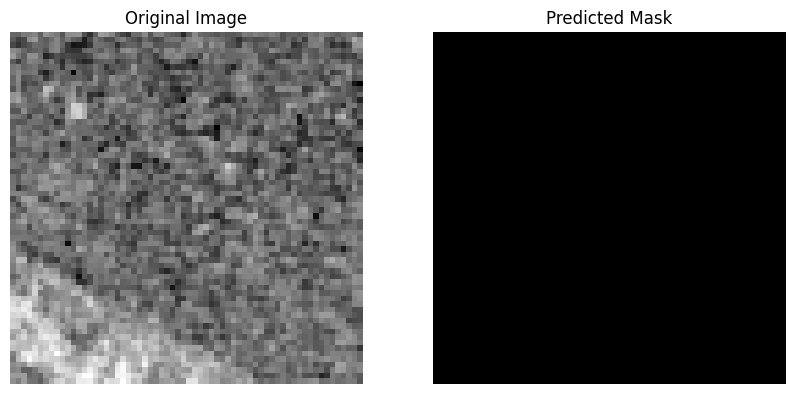

Predicting for im_1_1_17.npy...
(64, 64)
torch.Size([1, 3, 64, 64])


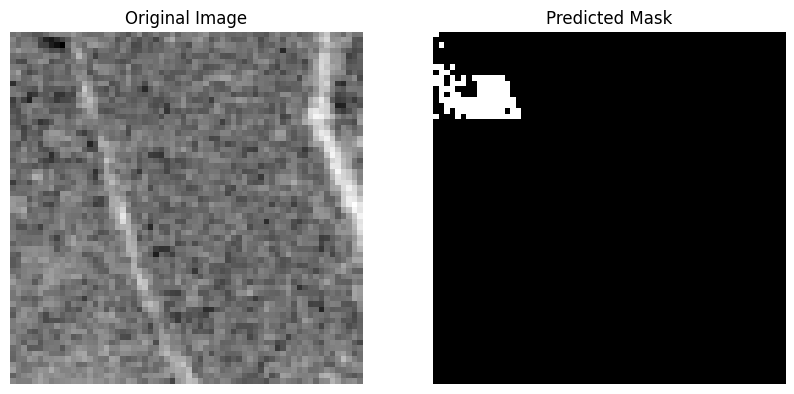

In [ ]:
import matplotlib.pyplot as plt
from torchvision import transforms
import torch
import torch.nn as nn  # Import torch.nn
import torch.optim as optim
from torchvision import transforms
import os
import numpy as np

# Define U-Net architecture (same as before)
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        # Encoder (downsampling)
        self.enc1 = self.conv_block(n_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        # Decoder (upsampling)
        self.dec1 = self.upconv(512, 256)
        self.dec2 = self.upconv(256, 128)
        self.dec3 = self.upconv(128, 64)
        self.dec4 = self.upconv(64, 64)
        self.dec5 = nn.Conv2d(64, n_classes, kernel_size=1)

        # Initialize with kaiming normal
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
                nn.init.kaiming_normal_(module.weight)

    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def upconv(self, in_ch, out_ch):
        return nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        # Decoder
        d1 = self.dec1(e4)
        d2 = self.dec2(d1)
        d3 = self.dec3(d2)
        d4 = self.dec4(d3)
        out = self.dec5(d4)

        return torch.sigmoid(out)

# Load the trained model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(n_channels=3, n_classes=1).to(device)
model.load_state_dict(torch.load('/content/drive/MyDrive/lake_segmentation_model_epoch_180.pth'))
model.eval()

# Define the folder where new data is stored
new_data_folder = '/content/drive/MyDrive/rashid_trials/time/2015/unfil/im_1'
file_names = [f for f in os.listdir(new_data_folder) if f.endswith('.npy')]

# Function to make predictions on a single image
def predict_and_visualize(file_name):
    # Load the image
    image_path = os.path.join(new_data_folder, file_name)
    image = np.load(image_path)

    if image.shape == (64, 64, 3):
        image = np.transpose(image, (2, 0, 1))  # Transpose to (3, 64, 64)

    # Convert to torch tensor
    image = torch.from_numpy(image).float().unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        output = model(image)
        # prediction = torch.squeeze(output).cpu().numpy()
        prediction = (torch.squeeze(output) > 0.2).float().cpu().numpy()

    # print(output.shape)
    print(prediction.shape)
    print(image.shape)
    # Visualize the original image and the predicted mask
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    ax[0].imshow(image.cpu().squeeze()[1,:,:], cmap='gray')
    ax[0].set_title('Original Image')
    ax[0].axis('off')

    ax[1].imshow(prediction, cmap='gray')
    ax[1].set_title('Predicted Mask')
    ax[1].axis('off')

    plt.show()

for i, file_name in enumerate(file_names[:50]):
    print(f'Predicting for {file_name}...')
    predict_and_visualize(file_name)
    # break

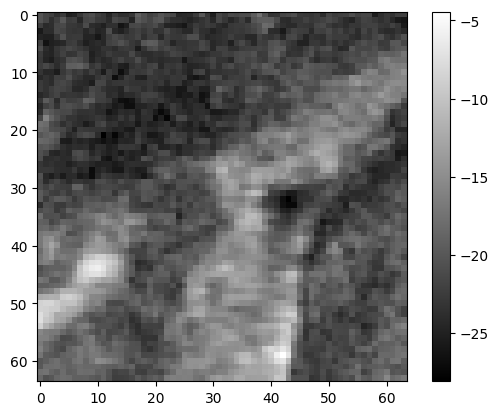

In [ ]:
import matplotlib.pyplot as plt
da='/content/drive/MyDrive/timeseries/2015/filtered_2015/im_1/patch_0.npy'
import numpy as np
a=np.load(da)
plt.imshow(a[:,:,0],cmap='gray')
plt.colorbar()
